![Banner](../../../../Images/Banner/03_spatial_analysis/03_02_banner_spatial_analysis_DTM.png)

# Terrain Derivatives and Morphometric Analysis

This notebook demonstrates core terrain analysis techniques using GeoLattice. You'll learn how to process digital elevation data, derive terrain attributes such as slope and aspect, and visualize various landform features within Python. The examples use real-world elevation data from Bangladesh and show how GeoLattice simplifies digital terrain modeling and spatial analysis workflows.


## Overview

Digital terrain analysis (DTA) derives morphometric attributes from a digital elevation model (DEM). From a gridded surface you can measure steepness and orientation, summarize local relief, describe curvature and relative position, estimate wetness, classify landforms, and map visibility and contours. Those products support erosion and landslide studies, site suitability, hydrologic context, and cartographic relief.

This notebook works through the terrain products in `geolattice.spatial_analysis.terrain_analysis`, in the order used below:

- Slope and aspect
- Hillshade
- Terrain Ruggedness Index (TRI), Topographic Position Index (TPI), and roughness
- Curvature surfaces
- Topographic Wetness Index (TWI)
- Landform classification and multiscale TPI
- Viewshed and contours

Flow routing, watershed delineation, and multi-criteria suitability are covered in later Module 03 notebooks.




This notebook uses `geolattice.spatial_analysis.terrain_analysis` with the Bangladesh
hilly-district DEM (`Data/00_shared/raster_data/Bangladesh/hilly_dem_BTM.tiff`, Bangladesh
Transverse Mercator, 250 m SRTM). It follows the topics in
`R_Code/terrain-analysis-r.qmd` and maps them to the Python API.

| Product | Backend | Notes |
|---|---|---|
| Slope, aspect, hillshade, TRI, TPI (3×3), roughness | GDAL `gdaldem` | First-order derivatives and roughness indices |
| Curvature, TWI, landform, multiscale, viewshed | NumPy | Whitebox-style geomorphometry |
| Contours | `gdal.ContourGenerateEx` | Vector elevation lines |

Outputs are written under `Data/00_shared/raster_data/output_folder/bangladesh/terrain`.


## API overview (`terrain_analysis`)

```
- slope: degrees or percent (gdaldem slope)
- aspect: 0-360° from north (gdaldem aspect)
- hillshade: shaded relief, optional multidirectional (gdaldem hillshade)
- tri: Terrain Ruggedness Index (gdaldem TRI)
- tpi: Topographic Position Index (gdaldem TPI or custom window)
- twi: Topographic Wetness Index ln(a / tan β)
- roughness: max - min in 3×3 (gdaldem roughness)
- curvature / mean_curvature / tangential_curvature /
  profile_curvature / plan_curvature / gaussian_curvature
- landform_classification: nested-TPI Weiss-style classes
- multiscale_analysis: metric across odd window sizes
- viewshed: line-of-sight visibility from observer(s)
- contours: vector elevation contours
```


## Setup

Locate the repository root, import terrain helpers, and create the output folder.

**Installation.** This notebook needs installation option 2 (core plus spatial analysis): `pip install "geolattice[analysis]"`. See "Installation options" in the GeoLattice README.

In [ ]:
# Display matplotlib figures inline in this Jupyter notebook.
%matplotlib inline

from pathlib import Path  # filesystem paths for locating the DEM and outputs

# Third-party numeric / plotting stack used throughout the notebook.
import matplotlib.pyplot as plt  # figure and axes creation for terrain maps
import numpy as np  # array ops (available for numeric checks)
import pandas as pd  # tabular display of summarize_raster results
from IPython.display import display  # rich table previews in the notebook

# ===================================================================
# Setup and helpers for terrain analysis.
# Import GeoLattice terrain helpers, point BD/OUT/DEM at sample paths, and define
# show_raster() for quick GeoTIFF summaries.
# ===================================================================

# The installed package lives in src/; the repository root is its parent.
import geolattice

ROOT = Path(geolattice.__file__).resolve().parents[1]
if not (ROOT / "Data").is_dir():
    raise FileNotFoundError("Could not find the GeoLattice repository root.")

# Raster I/O helpers used to inspect and clip the DEM.
from geolattice.raster import (
    clip,  # crop a raster to projected bounds
    open_raster_data,  # open a GeoTIFF for metadata / bounds
    summarize_raster,  # count/min/max/mean/percentiles
)
# Terrain analysis helpers used in the exercises below.
from geolattice.spatial_analysis import (
    aspect,  # slope aspect in degrees from north
    contours,  # elevation contour lines to a vector file
    curvature,  # generic curvature dispatcher
    gaussian_curvature,  # Gaussian curvature surface
    hillshade,  # shaded relief (single or multidirectional)
    landform_classification,  # nested-TPI landform classes
    mean_curvature,  # mean curvature surface
    multiscale_analysis,  # metric across a range of window sizes
    plan_curvature,  # plan (contour) curvature
    profile_curvature,  # profile (slope-line) curvature
    roughness,  # elevation range in a 3x3 window
    slope,  # slope in degrees or percent
    tangential_curvature,  # tangential curvature surface
    tpi,  # topographic position index
    tri,  # terrain ruggedness index
    twi,  # topographic wetness index
    viewshed,  # visible/hidden cells from an observer
)
from geolattice.viz import apply_map_style, plot_raster, plot_raster_histogram, plot_rasters  # map helpers

# Paths to the Bangladesh DEM and a dedicated terrain output folder.
BD = ROOT / "Data" / "00_shared" / "raster_data" / "Bangladesh"  # Bangladesh raster samples
OUT = ROOT / "Data" / "00_shared" / "raster_data" / "output_folder" / "bangladesh" / "terrain"  # write outputs here
OUT.mkdir(parents=True, exist_ok=True)  # create the output folder if needed
DEM = BD / "hilly_dem_BTM.tiff"  # 250 m BTM DEM for the hilly districts
assert DEM.exists(), f"Missing DEM: {DEM}"  # fail early if the DEM is absent

apply_map_style()  # apply the GeoLattice tutorial matplotlib map defaults


def show_raster(path, title=None):
    """Print a short metadata summary for a GeoTIFF."""
    path = Path(path)  # normalize to Path
    with open_raster_data(path) as ds:  # open for metadata only
        gt = ds.geotransform  # origin and pixel size
        print(f"path:    {path.name}")  # file name
        print(f"size:    {ds.width} x {ds.height}  bands={ds.band_count}")  # dimensions
        print(f"res:     {abs(gt[1]):.4f} x {abs(gt[5]):.4f}")  # pixel size
        print(f"bounds:  {ds.bounds}")  # geographic extent
        print(f"crs:     {ds.crs}")  # coordinate reference system
        print(f"nodata:  {ds.get_band(1).nodata}")  # nodata flag
        if title:
            print(f"title:   {title}")  # optional label


print(f"DEM:    {DEM}")  # confirm DEM path
print(f"Output: {OUT}")  # confirm output folder


DEM:    /home/zia207/Github/GeoLattice/Data/00_shared/raster_data/Bangladesh/hilly_dem_BTM.tiff
Output: /home/zia207/Github/GeoLattice/Data/00_shared/raster_data/output_folder/bangladesh/terrain


## Data

30 m SRTM elevation resampled to 250 m for the hilly districts of Bangladesh
(Bandarban / Chittagong Hill Tracts area), projected to Bangladesh Transverse
Mercator: the same local DEM used in the R notes
(`hilly_dem_BTM.tiff` / `terra::rast(...)`).


path:    hilly_dem_BTM.tiff
size:    521 x 1329  bands=1
res:     250.0000 x 250.0000
bounds:  Bounds(648050.3746814046, 295017.2625412984, 778300.3746814046, 627267.2625412983)
crs:     PROJCS["unknown",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",90],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",-2000000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
nodata:  nan
title:   Hilly districts DEM (BTM)


,value
count,310665
min,-7.796429
max,985.049622
mean,109.007889
std,129.049986
sum,33864935.903503
percentiles,"{'p2': 3.0354053211212157, 'p25': 29.240074157..."


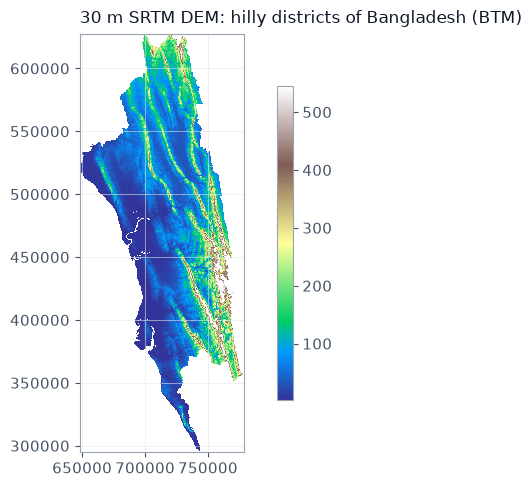

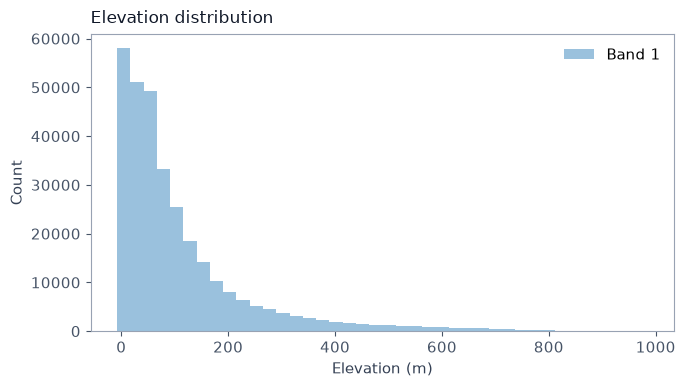

In [2]:
# Print DEM metadata and elevation summary statistics.
show_raster(DEM, "Hilly districts DEM (BTM)")  # path, size, CRS, nodata
stats = summarize_raster(DEM, percentiles=(2, 25, 50, 75, 98))  # robust percentiles
display(pd.Series(stats).to_frame("value"))  # show stats as a one-column table

# Terrain-colored map of the full Bangladesh hilly DEM.
ax = plot_raster(
    DEM,  # path to the elevation GeoTIFF
    title="30 m SRTM DEM: hilly districts of Bangladesh (BTM)",  # map title
    cmap="terrain",  # elevation-friendly colormap
    kind="general",  # single-band continuous display
    robust=True,  # percentile stretch for contrast
    show=False,  # defer display so we can call plt.show()
)
plt.show()  # render the DEM map

# Elevation histogram for the same DEM.
ax = plot_raster_histogram(DEM, bins=40, title="Elevation distribution", show=False)
ax.set_xlabel("Elevation (m)")  # label the x-axis with elevation units
plt.show()  # render the histogram


### Analysis window

The full mosaic is ~521 × 1329 cells. For heavier geomorphometry (TWI, multiscale,
viewshed) we clip a central window so the notebook stays responsive: the same
idea as the smaller AOI DEM in the R tutorial.


path:    aoi_dem.tif
size:    160 x 240  bands=1
res:     250.0000 x 250.0000
bounds:  Bounds(693175.3746814046, 431142.26254129835, 733175.3746814046, 491142.26254129835)
crs:     PROJCS["unknown",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",90],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",-2000000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
nodata:  nan
title:   Analysis AOI DEM


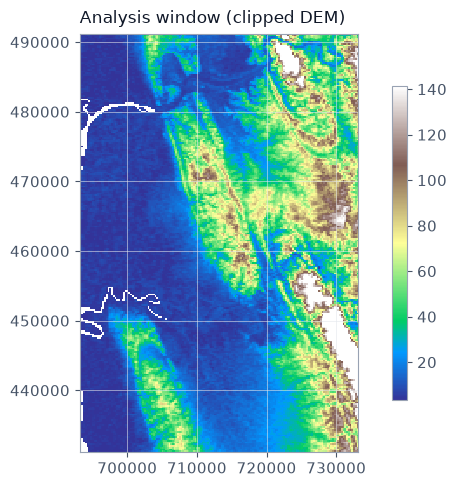

In [3]:
# Build a central analysis window (~40 km x 60 km) from the full DEM bounds.
with open_raster_data(DEM) as ds:
    b = ds.bounds  # full DEM extent in BTM metres
    # Central ~40 km x 60 km window in BTM metres.
    mid_x = 0.5 * (b.minx + b.maxx)  # horizontal center
    mid_y = 0.5 * (b.miny + b.maxy)  # vertical center
    half_x, half_y = 20000.0, 30000.0  # half-width and half-height in metres
    aoi_bounds = (mid_x - half_x, mid_y - half_y, mid_x + half_x, mid_y + half_y)  # clip window

dem = OUT / "aoi_dem.tif"  # destination path for the clipped AOI DEM
clip(DEM, dem, bounds=aoi_bounds, overwrite=True)  # crop the full DEM to the AOI
show_raster(dem, "Analysis AOI DEM")  # print clipped metadata

# Map the clipped analysis window.
ax = plot_raster(
    dem,  # clipped DEM path
    title="Analysis window (clipped DEM)",  # map title
    cmap="terrain",  # elevation colormap
    kind="general",  # single-band continuous display
    robust=True,  # percentile stretch
    show=False,  # defer display
)
plt.show()  # render the AOI map


## Slope

Slope measures the steepness or gradient of the land surface at any location, representing how quickly elevation changes across a given horizontal distance. It is commonly expressed either in degrees or as a percentage, revealing whether terrain is steep or gentle. 

Understanding slope is fundamental for terrain analysis because it directly affects water runoff, erosion potential, suitability for construction, agricultural planning, and assessment of natural hazards such as landslides. Accurate slope information is invaluable for fields like geography, geology, civil engineering, hydrology, and environmental science, guiding effective land management, risk mitigation, and infrastructure planning. 

By quantifying how elevation changes over distance, slope analysis helps model landscape processes, informs decision-making, and supports evidence-based practices in a variety of land use and environmental applications.

Slope can be represented in three main ways: as a ratio, a percentage, or an angle. Here's what each means:

Slope can be defined mathematically in several ways:

- **Slope Ratio:** The slope ratio quantifies the steepness as the ratio of vertical change ("rise") to horizontal distance ("run"):

  $$
  \text{Slope Ratio} = \frac{\text{rise}}{\text{run}}
  $$
  For example, if you ascend 1 meter (rise) over a horizontal distance of 2 meters (run), the slope ratio is $1:2$.

- **Slope Percentage:** Expresses the steepness as a percent, calculated by multiplying the slope ratio by 100:

  $$
  \text{Slope (\%)} = \left( \frac{\text{rise}}{\text{run}} \right) \times 100
  $$
  So a rise of 25 units over 100 units of run gives a slope of $(25/100) \times 100 = 25\%$.

- **Slope Angle (Degrees):** The slope angle, typically denoted $\theta$, is the angle between the horizontal and the slope. It can be calculated using the arctangent (inverse tangent) function:

  $$
  \theta = \arctan\left( \frac{\text{rise}}{\text{run}} \right)
  $$
  and is usually measured in degrees.

These three descriptions are mathematically equivalent, just expressed in different forms. 

- To convert from percentage or ratio to degrees: $\theta = \arctan(\text{Slope Ratio})$
- To convert from degrees to percent: $\text{Slope (\%)} = \tan(\theta) \times 100$

Where "rise" denotes the change in elevation between two points, and "run" denotes the horizontal distance between them.

Slope analysis is important for a wide variety of applications:

- **Erosion and Sediment Control:** Steeper slopes are more susceptible to erosion; understanding slope is vital for managing soil loss and sediment transport.
- **Land Use Planning:** Identifying appropriate areas for agriculture, construction, and infrastructure often relies on slope assessment.
- **Hydrology:** Slope determines the direction and speed of water flow, influencing drainage and runoff patterns.
- **Geological Studies:** Slope measurements help in evaluating rock stability and the likelihood of landslides or related phenomena.
- **Environmental Management:** Assessing the effects of land use changes on habitats and ecosystems involves understanding terrain slope.
- **Transportation Planning:** Designers use slope information to establish safe, efficient routes for roads, railways, and other infrastructure.

Digital terrain models (DTMs) and geographic information systems (GIS) are essential tools for slope analysis, enabling the creation of slope maps, the visualization of terrain, and evidence-based decision-making about landscape management.

In summary, slope describes the steepness of a surface, typically in degrees (0-90) or percent rise (rise/run × 100). Steeper slopes are especially significant in the context of erosion, landslides, and routing.

The function `slope(..., units="degrees"|"percent")` provides a convenient interface to the `gdaldem slope` tool.


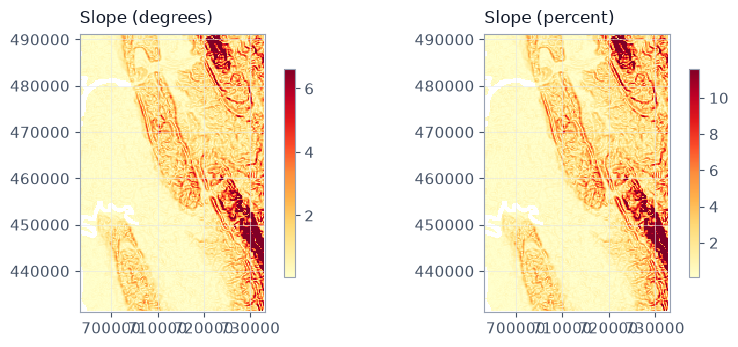

In [4]:
# Compute slope in degrees and percent rise for the AOI DEM.
slope_deg = OUT / "slope_degrees.tif"  # output path for slope in degrees
slope_pct = OUT / "slope_percent.tif"  # output path for slope in percent
slope(dem, slope_deg, units="degrees", overwrite=True)  # gdaldem-style slope degrees
slope(dem, slope_pct, units="percent", overwrite=True)  # percent rise = 100 * rise/run

# Side-by-side slope maps.
plot_rasters(
    [slope_deg, slope_pct],  # input paths
    titles=["Slope (degrees)", "Slope (percent)"],  # panel titles
    ncols=2,  # two columns
    cmap="YlOrRd",  # warm colormap for steepness
    robust=True,  # percentile stretch
    show=False,  # defer display
)
plt.show()  # render both panels


## Aspect

Aspect is a key quantitative parameter in terrain analysis that describes the compass direction a slope faces. Mathematically, aspect is the azimuth angle (θ) of the gradient vector, measured in degrees clockwise from north (0°). 

If the elevation $z$ is given as a gridded surface $z(x, y)$, then the aspect at any point is computed from the partial derivatives:

$$
\theta = \arctan2\left( \frac{\partial z}{\partial y}, -\frac{\partial z}{\partial x} \right)
$$

Where:  
- $\frac{\partial z}{\partial x}$ and $\frac{\partial z}{\partial y}$ are the east-west and north-south slopes (rate of elevation change per unit distance).
- The resulting θ is then converted to compass bearings (0° = north, 90° = east, 180° = south, 270° = west), and typically mapped into the range [0°, 360°).

Aspect is important because it affects the amount of sunlight, wind exposure, and precipitation a landscape receives. For example, a north-facing slope (aspect ≈ 0°) gets different solar radiation than a south-facing one (aspect ≈ 180°) in the Northern Hemisphere.

In more detail:

* **North (0°):** North-facing slopes get less direct sunlight, staying cooler and moister, often affecting plant growth, snow retention, and even soil temperature.
* **East (90°):** These slopes receive early morning sunlight, typically warming up earlier in the day, which can benefit plants that prefer cooler afternoons.
* **South (180°):** In the Northern Hemisphere, south-facing slopes are sunniest and driest, favoring plants that need warmth and leading to faster snowmelt.
* **West (270°):** Receive strong afternoon sun, often creating warmer late-day conditions.

Aspect analysis reveals critical spatial patterns and underpins decisions in:

1. **Solar radiation modeling:** Identifying warm and cold zones based on sun exposure, aiding in energy, agriculture, and climate models.
2. **Ecosystem and vegetation studies:** Understanding which plant communities are suited to specific slopes, as aspect shifts microclimates.
3. **Snow distribution:** Predicting where snow will melt first (south-facing) vs. linger longer (north-facing), important for hydrology and hazard assessment.
4. **Hydrology:** Mapping runoff patterns, water moves faster on sunny, drier slopes, helping with watershed management.
5. **Soil moisture and erosion:** Recognizing which slopes are at higher risk of drying and erosion, guiding land management.
6. **Wildlife habitat:** Many animal species choose habitats based on microclimate and shelter effects produced by aspect.
7. **Land use planning:** Guiding agriculture, forestry, and urban development by assessing suitability and risk tied to slope orientation.

Overall, aspect is integral to understanding landscape processes and making informed decisions in environmental science, resource management, and planning.

`aspect` wraps `gdaldem aspect`. Flat cells are typically nodata (-9999).


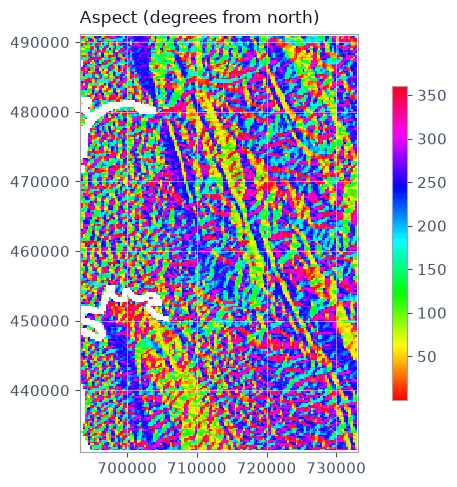

In [5]:
# Compute aspect (compass direction of the steepest downhill slope).
aspect_path = OUT / "aspect.tif"  # output path for aspect degrees
aspect(dem, aspect_path, overwrite=True)  # 0-360 degrees from north

# Map aspect with a cyclic HSV colormap.
ax = plot_raster(
    aspect_path,  # aspect GeoTIFF
    title="Aspect (degrees from north)",  # map title
    cmap="hsv",  # cyclic colormap for directions
    kind="general",  # single-band continuous display
    show=False,  # defer display
)
plt.show()  # render the aspect map


## Hillshade

Hillshade is a widely used cartographic and GIS technique for visually enhancing terrain maps by simulating the interplay of sunlight and shadow over elevation data. By creating the illusion of light striking the landscape's surface, hillshading adds realistic depth, making it easier to interpret topography and spatial landforms on otherwise flat, two-dimensional maps.

Most often applied to digital elevation models (DEMs) or digital terrain models (DTMs), hillshading models how sunlight would illuminate the surface. It casts shadows across slopes and highlights ridges and valleys, resulting in maps that are both informative and visually appealing. This approach is invaluable in numerous applications, including land use planning, environmental assessment, natural resource management, and outdoor recreation mapping.

The hillshade process typically involves several steps:

- **Illumination Angle:** A virtual sun position is selected (defined by azimuth and altitude angles), dictating the direction and height of the simulated light source relative to the terrain. Angles between 45° and 60° are frequently chosen for a natural balance of light and shadow.

- **Slope and Aspect Calculation:** For each pixel in the elevation grid, the slope (steepness) and aspect (direction the slope faces) are computed.

- **Shading Calculation:** Using these values, the intensity of light received by each pixel is determined. Slopes oriented away from the light source appear darker, simulating shadow, while those facing the sun appear brighter.

- **Grayscale Representation:** The final output is a raster where pixel values correspond to illumination intensity, typically rendered in grayscale. Brighter areas indicate higher exposure to the simulated sunlight, and darker areas represent shadows.

By applying hillshading to elevation data, mapmakers can produce terrain visualizations that closely match how landscapes look under actual sunlight from various directions. These realistic relief maps help users perceive surface features, such as valleys, ridges, slopes, and escarpments, with greater clarity.

Hillshade rasters are often overlaid with additional geographic layers (e.g., land cover, hydrology, infrastructure) to produce multilayered, easily interpreted maps that support deeper spatial analysis and richer cartographic storytelling.


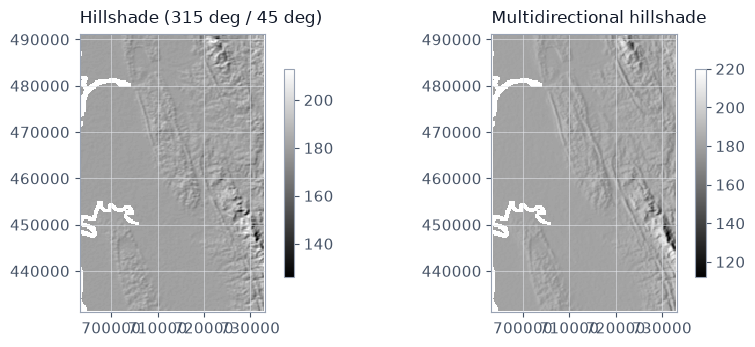

In [6]:
# Compute single-direction and multidirectional hillshade for cartographic relief.
hs = OUT / "hillshade.tif"  # single illumination hillshade
hs_md = OUT / "hillshade_multidirectional.tif"  # multidirectional hillshade
hillshade(dem, hs, azimuth=315, altitude=45, overwrite=True)  # NW sun at 45 deg elevation
hillshade(dem, hs_md, multidirectional=True, overwrite=True)  # blend multiple sun angles

# Side-by-side hillshade comparison.
plot_rasters(
    [hs, hs_md],  # input paths
    titles=["Hillshade (315 deg / 45 deg)", "Multidirectional hillshade"],  # panel titles
    ncols=2,  # two columns
    cmap="gray",  # grayscale relief
    show=False,  # defer display
)
plt.show()  # render both panels


## Terrain Ruggedness Index (TRI)

The Terrain Ruggedness Index (TRI) quantifies how much elevation changes between a grid cell and its surrounding neighbors, providing a measure of local topographic variability or roughness. This metric is especially valuable in landscape analysis, ecological modeling, geomorphology, and route planning, as it characterizes terrain complexity and heterogeneity.

**How TRI is calculated:**
1. **Window Selection:** Choose a window size (e.g., 3×3, 5×5, etc.) around each cell to define its neighborhood. Common sizes are 3×3 to 9×9 cells.
2. **Elevation Differences:** Compute the absolute elevation difference between the central cell and each neighboring cell within the window.
3. **Aggregation:** Sum (or average) these absolute differences across the window.
4. **Normalization:** Divide the total by the number of neighboring cells to standardize the result, making TRI values comparable across window sizes.

Mathematically, the commonly used formula is:

**TRI Formula:**

$$
\mathrm{TRI} = \frac{\sum \left| z_i - z_c \right|}{n}
$$

where:

- **$z_i$** = elevation of a neighboring cell  
- **$z_c$** = elevation of the central (target) cell  
- **$n$**   = number of neighboring cells (excluding the center)

**Interpretation:**  
- Higher TRI values indicate steeper, more rugged, and variable terrain.
- Lower TRI values reflect smoother, flatter, or more homogeneous landscapes.

**Applications of TRI:**
- **Ecology:** Assessing habitat diversity and wildlife connectivity
- **Geomorphology:** Identifying valleys, ridges, and highly variable landforms
- **Landscape Classification:** Differentiating between plains, slopes, and mountainous regions
- **Environmental Modeling:** Supporting models for erosion, hydrology, and sediment transport
- **Recreation & Planning:** Aiding in hiking route selection and risk evaluation for outdoor activities

In summary, TRI is a robust tool for quantifying and visualizing variation in elevation, helping researchers and planners better understand the complexity and functional characteristics of land surfaces.


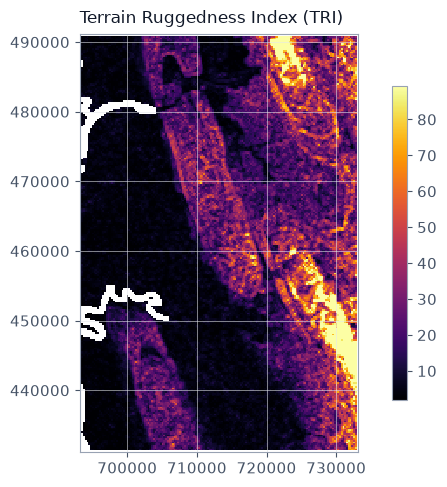

In [7]:
# Compute the Terrain Ruggedness Index using Riley's mean absolute difference.
tri_path = OUT / "tri.tif"  # output path for TRI
tri(dem, tri_path, algorithm="Riley", overwrite=True)  # Riley TRI in a 3x3 window

# Map TRI with a high-contrast inferno colormap.
ax = plot_raster(
    tri_path,  # TRI GeoTIFF
    title="Terrain Ruggedness Index (TRI)",  # map title
    cmap="inferno",  # high-contrast colormap
    kind="general",  # single-band continuous display
    robust=True,  # percentile stretch
    show=False,  # defer display
)
plt.show()  # render the TRI map


## Topographic Position Index (TPI)

The Topographic Position Index (TPI) quantifies how the elevation of a given cell compares to its neighboring landscape, making it easier to distinguish whether that location sits in a valley, on a ridge, or on flat ground. TPI is especially insightful for analyzing local terrain context and finds broad use in hydrology, ecological studies, landform classification, and beyond.

To calculate TPI, subtract the mean elevation of neighboring cells (within a defined window or radius) from the elevation of the central cell. The resulting value shows how much higher or lower the target cell is relative to its surroundings:
- Positive TPI: Indicates the cell is elevated above its neighbors, such as on a ridge or hilltop.
- Negative TPI: Indicates the cell is lower than neighbors, typically found in valleys or drainage areas.
- Near-zero TPI: Suggests the cell sits on flat or gently sloping terrain.

Calculation steps:
1. Define a neighborhood (square or circular) around the target cell.
2. Compute the mean elevation of all neighboring cells within this window.
3. Subtract this mean value from the central cell's elevation.

Mathematically:

$$\mathrm{TPI} = z_c - \left( \frac{\sum z_i}{n} \right)$$

where:
- $z_c$: elevation of the central (target) cell
- $z_i$: elevations of neighboring cells within the window
- $n$: number of neighboring cells

Key uses of TPI:
- Hydrology: Identifying ridges, drainage lines, and watershed boundaries
- Ecology: Mapping habitat variation, species distribution, and wildlife corridors
- Geomorphology: Landform classification and landscape analysis
- Soil and environmental sciences: Estimating potential wet areas and soil moisture patterns

By integrating TPI with other terrain metrics, you gain powerful insights into landscape structure, enabling more precise environmental modeling and landform interpretation at local scales.

TPI = elevation - mean of neighbours. Positive -> ridges / hilltops; negative ->
valleys; near zero -> flats or mid-slopes. The default 3×3 uses `gdaldem TPI`;
larger odd windows match the multi-scale TPI grids in the R notes.


/home/zia207/Github/GeoLattice/src/spatial_analysis/terrain_analysis.py:927: RuntimeWarning: Mean of empty slice
  return np.nanmean(masked, axis=(2, 3))


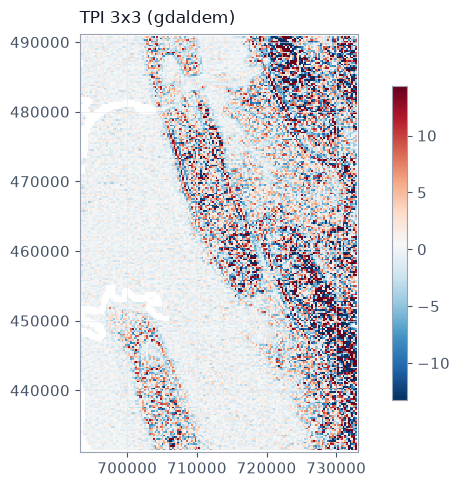

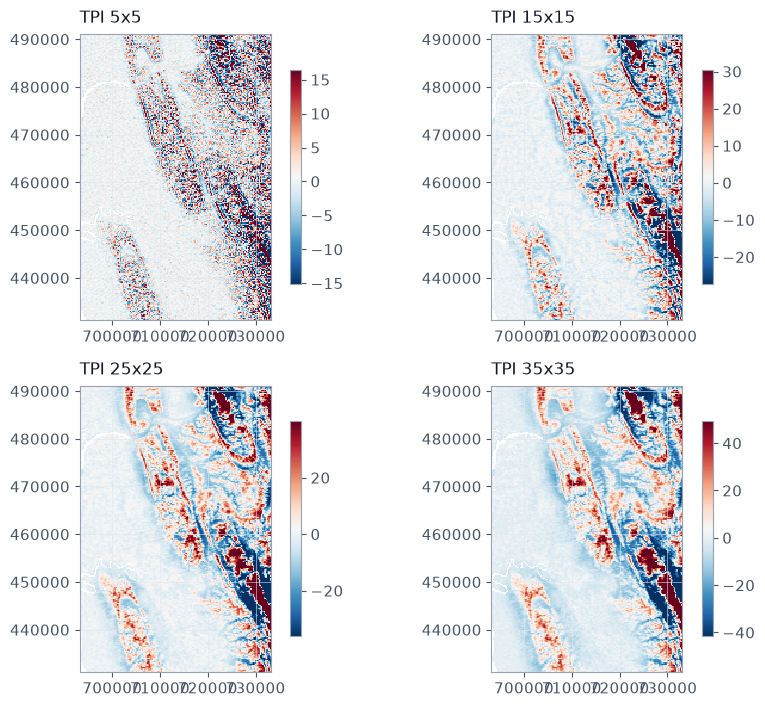

In [8]:
# Compute TPI at the default 3x3 window (gdaldem-style).
tpi3 = OUT / "tpi_3x3.tif"  # output path for 3x3 TPI
tpi(dem, tpi3, overwrite=True)  # gdaldem 3x3 topographic position index

# Nested windows (odd sizes), as in the R tpiw() examples.
tpi_paths = []  # collect TPI paths for a multi-panel plot
tpi_titles = []  # matching panel titles
for size in (5, 15, 25, 35):  # odd window sizes in cells
    path = OUT / f"tpi_{size}x{size}.tif"  # output path for this window
    tpi(dem, path, window_size=size, overwrite=True)  # TPI at this scale
    tpi_paths.append(path)  # remember path
    tpi_titles.append(f"TPI {size}x{size}")  # remember title

# Map the default 3x3 TPI first.
ax = plot_raster(tpi3, title="TPI 3x3 (gdaldem)", cmap="RdBu_r", robust=True, show=False)
plt.show()  # render the 3x3 TPI map

# Multi-panel map of nested-window TPI surfaces.
plot_rasters(
    tpi_paths,  # nested TPI paths
    titles=tpi_titles,  # panel titles
    ncols=2,  # two columns
    cmap="RdBu_r",  # diverging colormap (ridges vs valleys)
    robust=True,  # percentile stretch
    show=False,  # defer display
)
plt.show()  # render nested TPI panels


## Roughness

In terrain analysis, roughness describes the degree of unevenness or surface irregularity in the landscape. It quantifies how much elevations vary within a given area: highly rough terrain has sharp, frequent changes in elevation, while smooth terrain features gentle or gradual changes.

Several approaches are used to assess and represent terrain roughness; each method highlights different aspects of the landscape:

- **Standard Deviation of Elevation:** Calculates the spread of elevation values within a neighborhood or window. Higher standard deviation signifies more elevation variability and thus rougher terrain.

- **Root Mean Square (RMS) Slope:** Computes the square root of the mean of squared slope values in an area, capturing the average steepness. Higher RMS slope values reflect rougher, steeper terrain.

- **Slope Variance:** Assesses the variability of slope values; greater variance points to a more irregular and complex surface.

- **Elevation Range:** Measures the difference between the highest and lowest elevations in an area. A greater range indicates a wider span of elevation differences and increased roughness.

- **Texture Analysis:** Applies image processing or remote sensing techniques to DEMs to derive texture metrics, which reveal spatial patterns of elevation fluctuation.

- **Fractal Dimension:** Evaluates the complexity and scaling characteristics of terrain surfaces. Higher fractal dimensions indicate more intricate and rough landscapes.

Roughness metrics serve important roles in various disciplines:

- **Geomorphology:** Identifying and classifying landforms, such as ridges, valleys, and escarpments.
- **Engineering:** Informing the design and routing of infrastructure (e.g., roads, railways), as smoother terrain generally reduces construction complexity.
- **Environmental Science:** Understanding how roughness impacts hydrology, erosion, sediment transport, and flood potential.
- **Ecology:** Assessing habitat diversity and suitability, since terrain structure influences species distributions and biodiversity.
- **Land Use Planning:** Aiding in the optimal allocation of land based on topographic constraints, accessibility, and environmental impacts.

Roughness is typically calculated using GIS software and DEM or DTM datasets, supporting a wide range of analyses that require insights into the complexity and variability of Earth's surface.


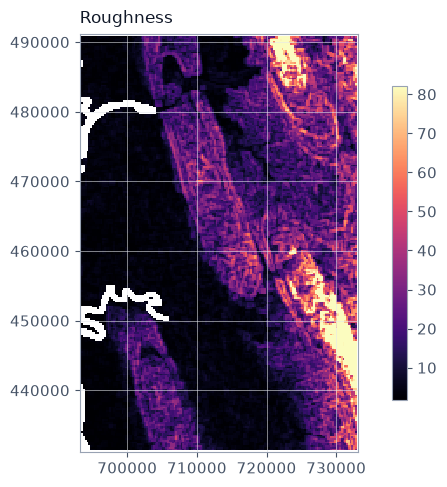

In [9]:
# Compute roughness as the elevation range within a local window.
rough_path = OUT / "roughness.tif"  # output path for roughness
roughness(dem, rough_path, overwrite=True)  # gdaldem-style roughness

# Map roughness with a magma colormap.
ax = plot_raster(
    rough_path,  # roughness GeoTIFF
    title="Roughness",  # map title
    cmap="magma",  # sequential colormap
    kind="general",  # single-band continuous display
    robust=True,  # percentile stretch
    show=False,  # defer display
)
plt.show()  # render the roughness map


## Curvature

Curvature, in the context of terrain analysis, refers to the rate of change of slope or the change in slope along a surface. It provides information about the concavity or convexity of the terrain at a specific location. Curvature analysis helps in understanding the local shape of the landscape and can provide insights into landforms, erosion patterns, and hydrological behavior.

Curvature is the rate of change of slope (second derivatives). Zevenbergen & Thorne
(1987) finite differences give:

- **Profile Curvature:** Denoted as $k_p$, the profile curvature is calculated in the direction of maximum slope (gradient), influencing flow acceleration/deceleration along a surface. It is mathematically given by:

  $$
  k_p = -\frac{z_{xx} p^2 + 2 z_{xy} p q + z_{yy} q^2}{(p^2 + q^2)^{3/2}}
  $$

  where $p = \frac{\partial z}{\partial x}$, $q = \frac{\partial z}{\partial y}$, $z_{xx} = \frac{\partial^2 z}{\partial x^2}$, $z_{yy} = \frac{\partial^2 z}{\partial y^2}$, and $z_{xy} = \frac{\partial^2 z}{\partial x \partial y}$. Positive values indicate convexity (ridges), negative values concavity (valleys).

- **Plan Curvature:** Denoted as $k_{pl}$, plan curvature is measured perpendicular to the direction of slope (along contours), affecting the convergence or divergence of flow:

  $$
  k_{pl} = \frac{z_{xx} q^2 - 2 z_{xy} p q + z_{yy} p^2}{(p^2 + q^2)^{3/2}}
  $$

  Here, positive values indicate convexity (divergence, crests), negative values concavity (convergence, hollows).

- **Tangential Curvature:** Often used interchangeably with plan curvature, but formally refers to curvature in the direction perpendicular to the slope (in the tangent plane to the surface):

  $$
  k_t = k_{pl}
  $$

  In most DEM analysis, "tangential" and "plan" curvature are computed using the same formula.

- **Mean Curvature:** Mean curvature $H$ at a surface point is the average of the principal curvatures (profile and plan):

  $$
  H = \frac{1}{2}(k_1 + k_2)
  $$

  In terrain analysis, it is commonly approximated as:

  $$
  H = \frac{k_p + k_{pl}}{2}
  $$

  It provides a general measure of how much the surface bends at that point.

- **Gaussian Curvature:** Gaussian curvature $K$ is the product of the principal curvatures:

  $$
  K = k_1 \cdot k_2
  $$

  For DEMs, $K$ can be derived via the determinants of the first and second fundamental forms or by:

  $$
  K = \frac{z_{xx}z_{yy} - z_{xy}^2}{(1 + p^2 + q^2)^2}
  $$

  Negative $K$ indicates a saddle, zero is flat, and positive values indicate peak or pit-like regions.


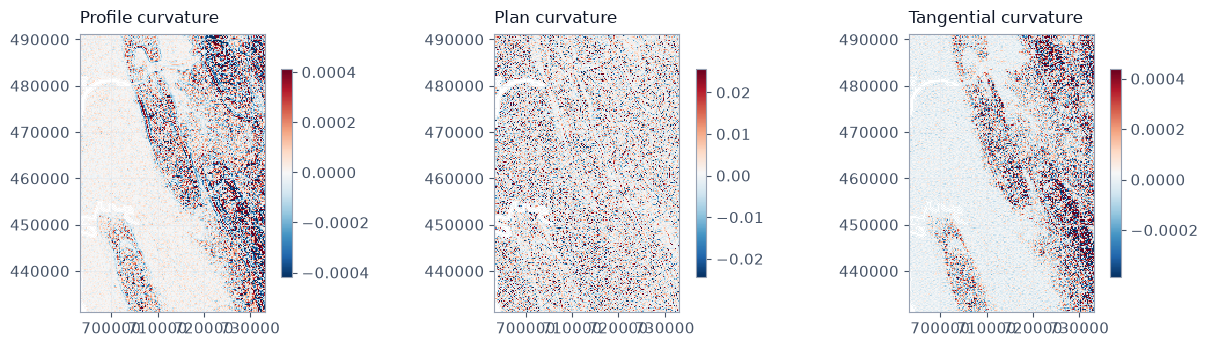

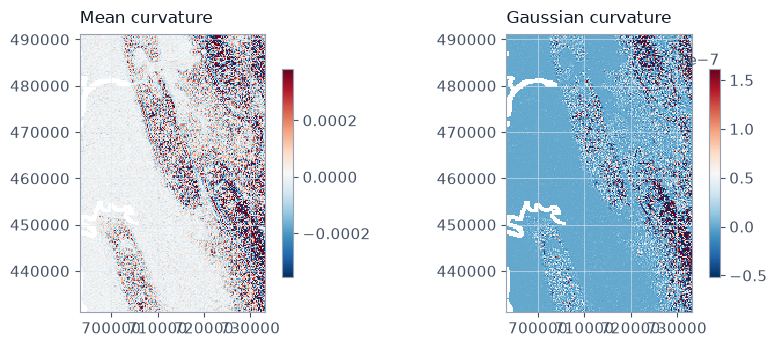

'/home/zia207/Github/GeoLattice/Data/00_shared/raster_data/output_folder/bangladesh/terrain/curvature_profile_alias.tif'

In [10]:
# Compute five curvature surfaces commonly used in geomorphometry.
curv_paths = []  # collect output paths
curv_titles = []  # collect panel titles
for kind, fn in [
    ("profile", profile_curvature),  # curvature along the slope line
    ("plan", plan_curvature),  # curvature of contour lines
    ("tangential", tangential_curvature),  # curvature perpendicular to slope
    ("mean", mean_curvature),  # average of principal curvatures
    ("gaussian", gaussian_curvature),  # product of principal curvatures
]:
    path = OUT / f"curvature_{kind}.tif"  # output path for this curvature type
    fn(dem, path, overwrite=True)  # compute and write the surface
    curv_paths.append(path)  # remember path
    curv_titles.append(f"{kind.capitalize()} curvature")  # remember title

# First row: profile, plan, and tangential curvature.
plot_rasters(
    curv_paths[:3],  # first three curvature rasters
    titles=curv_titles[:3],  # matching titles
    ncols=3,  # three columns
    cmap="RdBu_r",  # diverging colormap
    robust=True,  # percentile stretch
    show=False,  # defer display
)
plt.show()  # render the first curvature row

# Second row: mean and Gaussian curvature.
plot_rasters(
    curv_paths[3:],  # remaining curvature rasters
    titles=curv_titles[3:],  # matching titles
    ncols=2,  # two columns
    cmap="RdBu_r",  # diverging colormap
    robust=True,  # percentile stretch
    show=False,  # defer display
)
plt.show()  # render the second curvature row

# Equivalent generic API for profile curvature (alias of profile_curvature).
curvature(dem, OUT / "curvature_profile_alias.tif", curvature_type="profile", overwrite=True)


## Topographic Wetness Index (TWI)

The Topographic Wetness Index (TWI) is a widely used hydrological index that quantifies the effect of local topography on the location and extent of soil moisture and potential saturation zones. It is calculated using the formula:

    TWI = ln(a / tan β)

where:
- *a* is the specific catchment area (the local upslope area draining through each point per unit contour length), typically derived from flow accumulation using the D8 algorithm.
- *β* is the local slope angle (in radians) at each cell.

High TWI values indicate areas that are likely to be wetter or more saturated, such as valley bottoms, depressions, or zones where surface or subsurface water accumulates. Conversely, low TWI values correspond to ridges or well-drained slopes.

In this notebook, TWI is calculated using functions from the `terrain_analysis` module, which automates the computation of upslope area (flow accumulation) and local slope for each DEM cell. This is different from the approach in the referenced R notes, where flow direction is calculated explicitly as part of the process. Here, TWI acts as an integrative hydrological indicator, helpful for environmental modeling, hydrology, and land suitability studies.


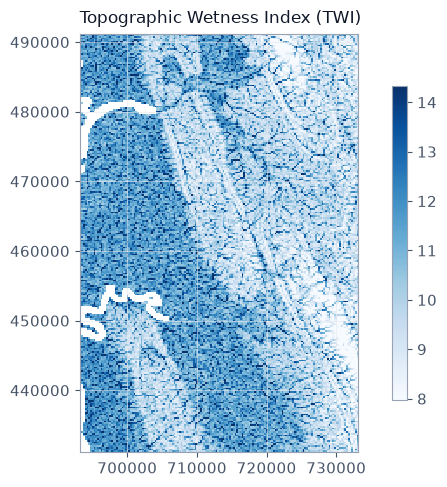

In [11]:
# Compute the Topographic Wetness Index (upslope area and local slope).
twi_path = OUT / "twi.tif"  # output path for TWI
twi(dem, twi_path, overwrite=True)  # write the TWI surface

# Map TWI with a blue sequential colormap.
ax = plot_raster(
    twi_path,  # TWI GeoTIFF
    title="Topographic Wetness Index (TWI)",  # map title
    cmap="Blues",  # wetness-friendly colormap
    kind="general",  # single-band continuous display
    robust=True,  # percentile stretch
    show=False,  # defer display
)
plt.show()  # render the TWI map


## Landform classification

Landform classification identifies different geomorphic landforms (such as valleys, ridges, slopes, and flats) using a combination of the Topographic Position Index (TPI) calculated at multiple spatial scales and local slope. 
Specifically, the method computes TPI using both a small window and a large window for each cell in the DEM:
- The small-window TPI highlights fine-scale landform features (e.g., small ridges or depressions).
- The large-window TPI captures broader-scale terrain positions (e.g., major valleys or hilltops).

By comparing a cell's elevation to its surroundings at both scales, and incorporating the local slope, this "nested TPI" method assigns each cell a landform class according to the Weiss (2001) scheme.

Typical classes produced include: Valley, Lower Slope, Flat, Middle Slope, Upper Slope, Local Ridge, and High Ridge.


Classes: {1: 'valley', 2: 'lower_slope', 3: 'gentle_slope', 4: 'steep_slope', 5: 'upper_slope', 6: 'ridge', 7: 'flat'}


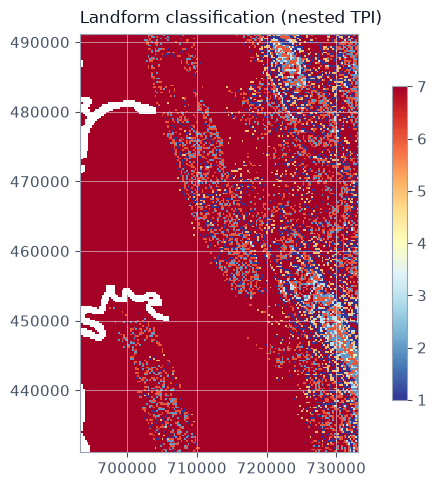

In [12]:
# Classify landforms from nested small/large TPI windows and a slope threshold.
lf = landform_classification(
    dem,  # AOI DEM
    OUT / "landforms.tif",  # categorical landform output
    small_window=3,  # fine-scale TPI window (cells)
    large_window=35,  # coarse-scale TPI window (cells)
    slope_threshold=5.0,  # degrees; separates flats from slopes
    overwrite=True,  # replace any previous landform file
)
print("Classes:", lf["classes"])  # print the class name lookup

# Map categorical landforms with a diverging colormap.
ax = plot_raster(
    lf["path"],  # landform GeoTIFF path
    title="Landform classification (nested TPI)",  # map title
    cmap="RdYlBu_r",  # categorical-friendly colormap
    kind="general",  # display mode
    categories=lf["classes"],  # class labels for the legend
    show=False,  # defer display
)
plt.show()  # render the landform map


## Multiscale analysis

Many geomorphic properties of terrain, such as topographic position, roughness, TRI (Terrain Ruggedness Index), and mean curvature, vary depending on the scale at which they are calculated. 
The `multiscale_analysis` function allows you to systematically analyze these metrics at multiple spatial scales by computing the chosen metric using several odd-sized window kernels (e.g., 3x3, 7x7, ..., up to the maximum specified scale). 
For each cell in the DEM, the function calculates the metric at all these scales. The main result is typically:
  - a map of the maximum absolute value (|response|) of the metric across scales for each cell,
  - a corresponding "scale map" indicating at which window size this maximum response occurred,
  - or, if requested, a stack showing all computed bands (one per window size).
This multiscale approach is valuable for detecting landforms and terrain features whose prominence depends on the spatial context, helping to reveal both small- and large-scale patterns in the landscape.


{'value': '/home/zia207/Github/GeoLattice/Data/00_shared/raster_data/output_folder/bangladesh/terrain/ms_tpi.tif', 'scale': '/home/zia207/Github/GeoLattice/Data/00_shared/raster_data/output_folder/bangladesh/terrain/ms_tpi_scale.tif'}


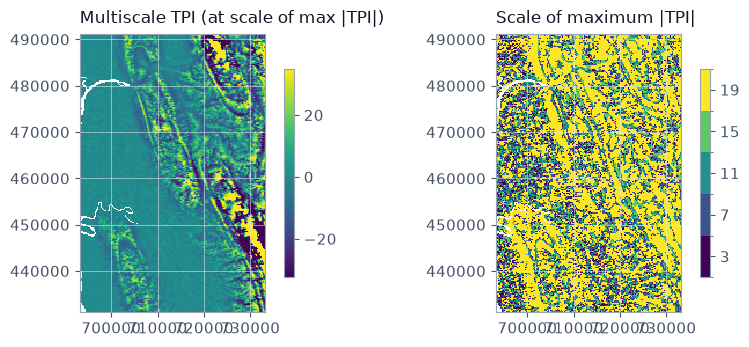

In [13]:
# Compute TPI across multiple window sizes and keep the scale of maximum |TPI|.
ms = multiscale_analysis(
    dem,  # AOI DEM
    OUT / "ms_tpi.tif",  # base output path (value + scale companions)
    metric="tpi",  # geomorphometric metric to evaluate
    min_scale=3,  # smallest odd window size
    max_scale=21,  # largest odd window size
    step=4,  # step between window sizes
    output="max",  # keep the scale of maximum absolute TPI
    overwrite=True,  # replace previous multiscale outputs
)
print(ms)  # print the returned path dictionary

# Side-by-side: multiscale TPI value and the scale at which it peaks.
plot_rasters(
    [ms["value"], ms["scale"]],  # value and scale rasters
    titles=["Multiscale TPI (at scale of max |TPI|)", "Scale of maximum |TPI|"],  # panel titles
    ncols=2,  # two columns
    cmap="viridis",  # sequential colormap
    robust=True,  # percentile stretch
    show=False,  # defer display
)
plt.show()  # render both panels


## Viewshed

A viewshed identifies which locations (cells) in a DEM are visible from a specific observer position, based on line-of-sight analysis. 
For this example, we select an observer located near the center of the AOI, ideally placed on a ridge or high elevation point.
The `observer_height` parameter lets you specify the height (in meters) of the observer above the DEM surface (e.g., the height of a person or structure).
Every cell is checked to determine whether it is visible to this observer, taking terrain obstruction into account: areas blocked by intervening hills/mountains are not visible, and the result is a binary raster showing visible (1) and not visible (0) areas.
This type of analysis is commonly used for applications like communication tower siting, landscape planning, or determining the visual impact of new developments.


Observer pixel (120, 80) -> (713300.4, 461017.3)


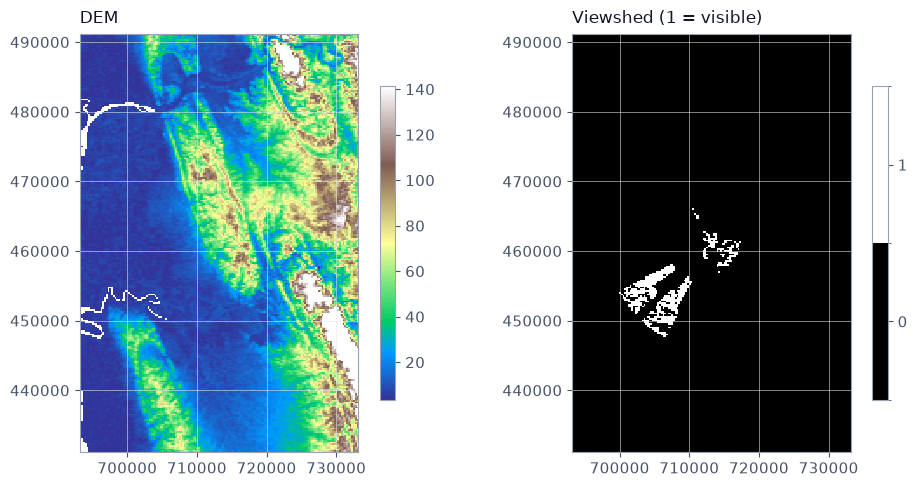

In [14]:
# Place an observer near the AOI centre and compute a binary viewshed.
with open_raster_data(dem) as ds:
    gt = ds.geotransform  # origin and pixel size
    # Map coordinates of a cell near the centre.
    row, col = ds.height // 2, ds.width // 2  # centre pixel indices
    obs_x = gt[0] + (col + 0.5) * gt[1]  # observer X (map units)
    obs_y = gt[3] + (row + 0.5) * gt[5]  # observer Y (map units)
    print(f"Observer pixel ({row}, {col}) -> ({obs_x:.1f}, {obs_y:.1f})")  # confirm location

vs_path = OUT / "viewshed.tif"  # output path for the viewshed mask
viewshed(
    dem,  # AOI DEM
    vs_path,  # binary visible/hidden output
    observer=(obs_x, obs_y),  # observer map coordinates
    observer_height=1.8,  # eye height in metres
    max_distance=15000,  # search radius in metres
    overwrite=True,  # replace any previous viewshed
)

# Side-by-side DEM and viewshed.
fig, axes = plt.subplots(1, 2, figsize=(10, 5))  # two-panel figure
plot_raster(dem, ax=axes[0], title="DEM", cmap="terrain", robust=True, show=False)  # left: DEM
plot_raster(vs_path, ax=axes[1], title="Viewshed (1 = visible)", cmap="gray", show=False)  # right: viewshed
plt.tight_layout()  # reduce unused whitespace
plt.show()  # render both panels


## Contours

Elevation contours are vector lines that connect points of equal elevation on the terrain surface. 
These contours are generated from the DEM using the GDAL tool `gdal_contour` (accessible via `ContourGenerateEx` in the API).
The process works by interpolating the raster elevation values and extracting continuous lines at set elevation intervals (e.g., every 50 meters).
Contour lines provide an intuitive way to visualize topography, showing both the shape of the landscape and gradients: 
closely spaced contours indicate steep slopes, while widely spaced lines mark gentle or flat areas.
These vectors are commonly used for topographic mapping, landscape analysis, and as overlays on maps to clarify elevation structure.
Here, we generate a set of contours from the DEM in GeoPackage format, then overlay them on the raster DEM for visualization.


Wrote /home/zia207/Github/GeoLattice/Data/00_shared/raster_data/output_folder/bangladesh/terrain/contours.gpkg


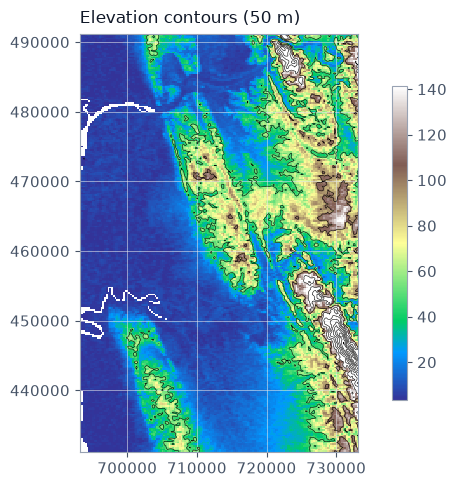

In [15]:
# Extract 50 m elevation contours from the AOI DEM to a GeoPackage.
contour_path = OUT / "contours.gpkg"  # vector output path
contours(dem, contour_path, interval=50.0, overwrite=True)  # 50 m contour interval
print(f"Wrote {contour_path}")  # confirm write

# Overlay contours on the DEM (requires geopandas).
try:
    import geopandas as gpd  # vector overlay for contour lines

    lines = gpd.read_file(contour_path)  # load contour geometries
    ax = plot_raster(dem, title="Elevation contours (50 m)", cmap="terrain", robust=True, show=False)
    lines.plot(ax=ax, color="k", linewidth=0.4)  # black contour lines
    plt.show()  # render DEM + contours
except ImportError:
    print("Install geopandas (geolattice[viz] or [io]) to overlay contour lines.")  # optional dependency note


## Summary

| Step | Function | Output |
|---|---|---|
| Slope ° / % | `slope` | `slope_degrees.tif`, `slope_percent.tif` |
| Aspect | `aspect` | `aspect.tif` |
| Hillshade | `hillshade` | `hillshade.tif`, `hillshade_multidirectional.tif` |
| TRI | `tri` | `tri.tif` |
| TPI | `tpi` | `tpi_*.tif` |
| Roughness | `roughness` | `roughness.tif` |
| Curvature | `profile_curvature`, … | `curvature_*.tif` |
| TWI | `twi` | `twi.tif` |
| Landforms | `landform_classification` | `landforms.tif` |
| Multiscale | `multiscale_analysis` | `ms_tpi.tif`, `ms_tpi_scale.tif` |
| Viewshed | `viewshed` | `viewshed.tif` |
| Contours | `contours` | `contours.gpkg` |

### Further reading

1. [Whitebox terrain analysis / geomorphometry](https://www.whiteboxgeo.com/manuals/api/python/terrain-analysis.html)
2. [gdaldem](https://gdal.org/en/stable/programs/gdaldem.html)
3. R notes: `R_Code/terrain-analysis-r.qmd`
4. [Elevation data processing and analysis in R](https://rpubs.com/ials2un/dem_analysis)
5. [Geomorphometric variables calculation](https://rpubs.com/ials3/dem1)


In [16]:
# List every file written to the terrain output folder.
print("Terrain outputs:")  # section header
for path in sorted(OUT.glob("*")):  # sorted listing of OUT contents
    print(f"  {path.name}")  # print each file name


Terrain outputs:
  aoi_dem.tif
  aspect.tif
  contours.gpkg
  curvature_gaussian.tif
  curvature_mean.tif
  curvature_plan.tif
  curvature_profile.tif
  curvature_profile_alias.tif
  curvature_tangential.tif
  hillshade.tif
  hillshade_multidirectional.tif
  landforms.tif
  ms_tpi.tif
  ms_tpi_scale.tif
  roughness.tif
  slope_degrees.tif
  slope_percent.tif
  tpi_15x15.tif
  tpi_25x25.tif
  tpi_35x35.tif
  tpi_3x3.tif
  tpi_5x5.tif
  tri.tif
  twi.tif
  viewshed.tif
